<a href="https://colab.research.google.com/github/riasad30/Thesis/blob/main/final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# =====================================================================
# CODE 1: Apply SMOTE to the FULL dataset and save it as a new dataset
# Google Colab
# =====================================================================
# Before running: upload "default_of_credit_card_clients.xls" in the
# Colab Files panel (left sidebar → folder icon → upload).

!pip install -q imbalanced-learn xlrd

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

FILE_PATH = "/content/default of credit card clients.xls"   # change if your file is elsewhere
OUTPUT_PATH = "/content/credit_card_smote.csv"
TARGET = "default payment next month"
RANDOM_STATE = 42

# ---------- 1. Load data ----------
df = pd.read_excel(FILE_PATH, header=1)        # row 0 of the file is an extra header (X1, X2, ...)
df = df.drop(columns=["ID"])
X = df.drop(columns=[TARGET])
y = df[TARGET]

print("Original shape:", X.shape)
print("Original class counts:\n", y.value_counts().sort_index(), "\n")

# ---------- 2. SMOTE on the full dataset ----------
# Scale first so SMOTE's nearest-neighbour distances are fair across columns
# (LIMIT_BAL is in the hundreds of thousands, SEX is 1/2).
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

smote = SMOTE(k_neighbors=5, random_state=RANDOM_STATE)
X_res_scaled, y_res = smote.fit_resample(X_scaled, y)

# Convert back to the original units so the new dataset is readable
X_res = pd.DataFrame(scaler.inverse_transform(X_res_scaled), columns=X.columns)

df_smote = X_res.copy()
df_smote[TARGET] = y_res.values

print("After SMOTE shape:", df_smote.shape)
print("After SMOTE class counts:\n", df_smote[TARGET].value_counts().sort_index())
print("Synthetic rows added:", len(df_smote) - len(df))

# ---------- 3. Save the new dataset ----------
df_smote.to_csv(OUTPUT_PATH, index=False)
print("\nSaved:", OUTPUT_PATH)
display(df_smote.head())

# Optional: download the file to your computer
# from google.colab import files
# files.download(OUTPUT_PATH)

Original shape: (30000, 23)
Original class counts:
 default payment next month
0    23364
1     6636
Name: count, dtype: int64 

After SMOTE shape: (46728, 24)
After SMOTE class counts:
 default payment next month
0    23364
1    23364
Name: count, dtype: int64
Synthetic rows added: 16728

Saved: /content/credit_card_smote.csv


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,20000.0,2.0,2.0,1.0,24.0,2.0,2.0,-1.0,-1.0,-2.0,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,120000.0,2.0,2.0,2.0,26.0,-1.0,2.0,0.0,0.0,0.0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,90000.0,2.0,2.0,2.0,34.0,0.0,0.0,0.0,0.0,0.0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,50000.0,2.0,2.0,1.0,37.0,0.0,0.0,0.0,0.0,0.0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,50000.0,1.0,2.0,1.0,57.0,-1.0,0.0,-1.0,0.0,0.0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


Train: 37382 rows | Test: 9346 rows
Test class counts: {0: 4664, 1: 4682} 

ExtraTrees: accuracy = 0.8893  (19.3s)
RandomForest: accuracy = 0.8523  (37.3s)
Bagging: accuracy = 0.8340  (12.6s)
KNeighbors: accuracy = 0.7786  (2.2s)
DecisionTree: accuracy = 0.7600  (1.4s)
AdaBoost: accuracy = 0.7275  (6.0s)
SVC: accuracy = 0.7130  (101.8s)
LogisticRegression: accuracy = 0.6665  (0.3s)

CLASS-WISE RESULTS (test set)

----- ExtraTrees -----
                      precision    recall  f1-score   support

Class 0 (No default)     0.8901    0.8877    0.8889      4664
   Class 1 (Default)     0.8884    0.8909    0.8896      4682

            accuracy                         0.8893      9346
           macro avg     0.8893    0.8893    0.8893      9346
        weighted avg     0.8893    0.8893    0.8893      9346


----- RandomForest -----
                      precision    recall  f1-score   support

Class 0 (No default)     0.8323    0.8819    0.8563      4664
   Class 1 (Default)     0.8749   

Overall   Class 0                          Class 1         \
                   Accuracy Precision Recall     F1 Accuracy Precision Recall   
Model                                                                           
ExtraTrees            88.93     89.01  88.77  88.89    88.77     88.84  89.09   
RandomForest          85.23     83.23  88.19  85.63    88.19     87.49  82.29   
Bagging               83.40     80.08  88.85  84.24    88.85     87.53  77.98   
KNeighbors            77.86     85.36  67.15  75.17    67.15     73.01  88.53   
DecisionTree          76.00     76.68  74.59  75.62    74.59     75.36  77.40   
AdaBoost              72.75     69.07  82.20  75.07    82.20     78.13  63.33   
SVC                   71.30     67.05  83.58  74.40    83.58     78.31  59.08   
LogisticRegression    66.65     65.91  68.70  67.28    68.70     67.45  64.61   

                                    
                       F1 Accuracy  
Model                               
ExtraTrees          88.96    89.09  
RandomForest        84.81    82.29  
Bagging             82.48    77.98  
KNeighbors          80.03    88.53  
DecisionTree        76.37    77.40  
AdaBoost            69.95    63.33  
SVC                 67.35    59.08  
LogisticRegression  66.00    64.61

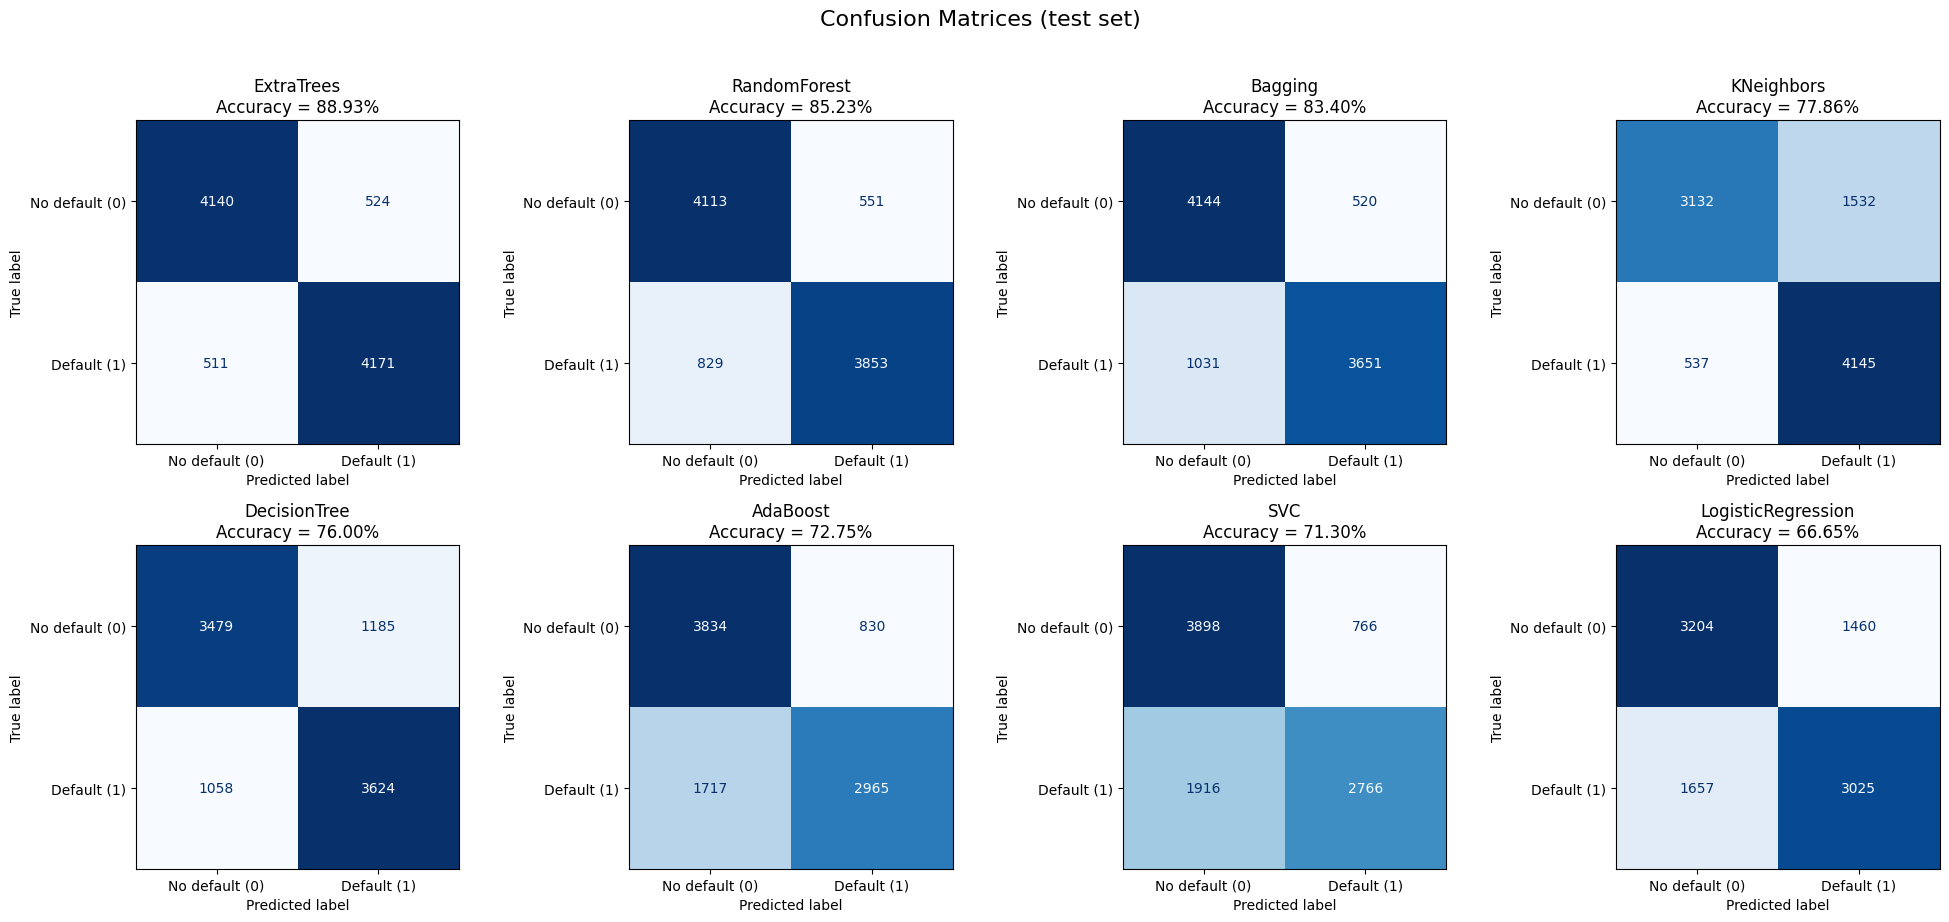

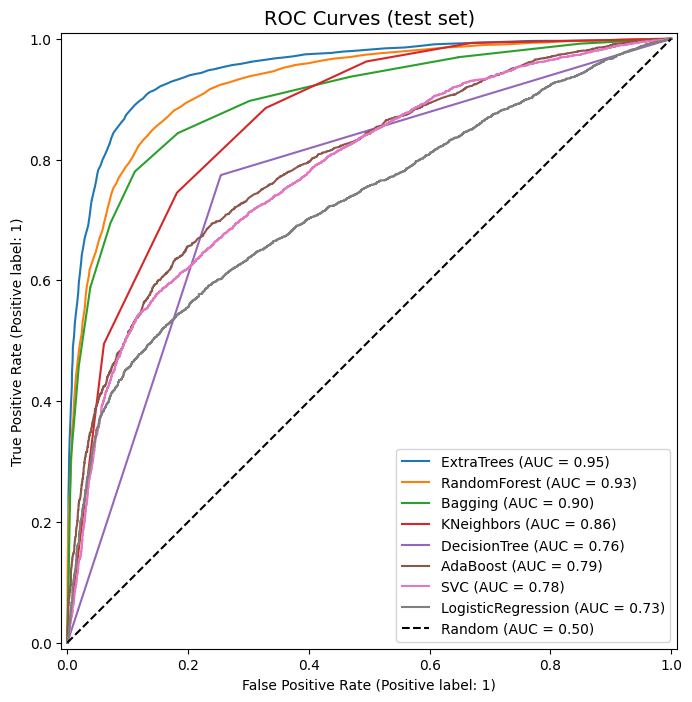


Best model on the test set: ExtraTrees (0.8893)

5-Fold Cross-Validation Accuracy — ExtraTrees
  Fold 1: 0.8933
  Fold 2: 0.8900
  Fold 3: 0.8910
  Fold 4: 0.8856
  Fold 5: 0.8920
  Mean : 0.8904
  Std  : 0.0026


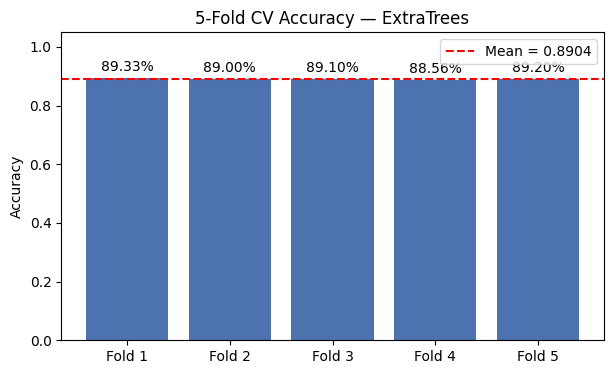

In [2]:
# =====================================================================
# CODE 2: Train 8 models on the SMOTE dataset (from Code 1)
#   - 80/20 train/test split
#   - Class-wise precision / recall / F1 / accuracy (class 0 and class 1)
#   - Confusion matrix plots
#   - ROC curves
#   - 5-fold cross-validation accuracy for the best model
# Google Colab — run Code 1 first (it creates /content/credit_card_smote.csv)
# =====================================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

DATA_PATH = "/content/credit_card_smote.csv"
TARGET = "default payment next month"
RANDOM_STATE = 42

# ---------- 1. Load SMOTE dataset & split 80/20 ----------
df = pd.read_csv(DATA_PATH)
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")
print("Test class counts:", y_test.value_counts().sort_index().to_dict(), "\n")

# ---------- 2. Models ----------
models = {
    "ExtraTrees":         ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "RandomForest":       RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "Bagging":            BaggingClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "KNeighbors":         KNeighborsClassifier(),
    "DecisionTree":       DecisionTreeClassifier(random_state=RANDOM_STATE),
    "AdaBoost":           AdaBoostClassifier(random_state=RANDOM_STATE),
    "SVC":                SVC(random_state=RANDOM_STATE),            # slowest (~1-2 min)
    "LogisticRegression": LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
}

def make_pipeline(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])









# ---------- 3. Train, predict, class-wise metrics ----------
fitted, rows = {}, []
for name, model in models.items():
    t0 = time.time()
    pipe = make_pipeline(model).fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    fitted[name] = (pipe, y_pred)

    prec, rec, f1, sup = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1], zero_division=0)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    class_acc = cm.diagonal() / cm.sum(axis=1)



      # per-class accuracy (= recall of that class)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Class 0 Precision": prec[0], "Class 0 Recall": rec[0], "Class 0 F1": f1[0], "Class 0 Accuracy": class_acc[0],
        "Class 1 Precision": prec[1], "Class 1 Recall": rec[1], "Class 1 F1": f1[1], "Class 1 Accuracy": class_acc[1],
        "Time (s)": time.time() - t0,
    })
    print(f"{name}: accuracy = {rows[-1]['Accuracy']:.4f}  ({rows[-1]['Time (s)']:.1f}s)")

results = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)

# ---------- 4. Class-wise result for every model ----------
print("\n" + "=" * 70)
print("CLASS-WISE RESULTS (test set)")
print("=" * 70)
for name in results["Model"]:
    _, y_pred = fitted[name]
    print(f"\n----- {name} -----")
    print(classification_report(y_test, y_pred, labels=[0, 1],
                                target_names=["Class 0 (No default)", "Class 1 (Default)"], digits=4))

# Summary table: class 0 and class 1 for each model
summary = results.set_index("Model")
class_table = pd.concat({
    "Class 0": summary[["Class 0 Precision", "Class 0 Recall", "Class 0 F1", "Class 0 Accuracy"]]
               .set_axis(["Precision", "Recall", "F1", "Accuracy"], axis=1),
    "Class 1": summary[["Class 1 Precision", "Class 1 Recall", "Class 1 F1", "Class 1 Accuracy"]]
               .set_axis(["Precision", "Recall", "F1", "Accuracy"], axis=1),
}, axis=1)
class_table.insert(0, ("Overall", "Accuracy"), summary["Accuracy"])
print("\nSUMMARY TABLE (%)")
display((class_table * 100).round(2))

results.to_csv("/content/model_results_classwise.csv", index=False)

# ---------- 5. Confusion matrix plots ----------
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, name in zip(axes.ravel(), results["Model"]):
    _, y_pred = fitted[name]
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=[0, 1], display_labels=["No default (0)", "Default (1)"],
        cmap="Blues", colorbar=False, values_format="d", ax=ax)
    acc = results.loc[results["Model"] == name, "Accuracy"].item()
    ax.set_title(f"{name}\nAccuracy = {acc:.2%}", fontsize=12)
plt.suptitle("Confusion Matrices (test set)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# ---------- 6. ROC curves (all models on one plot) ----------
fig, ax = plt.subplots(figsize=(9, 8))
for name in results["Model"]:
    pipe, _ = fitted[name]
    # uses predict_proba when available, otherwise decision_function (e.g. SVC)
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.50)")
ax.set_title("ROC Curves (test set)", fontsize=14)
ax.legend(loc="lower right")
plt.show()

# ---------- 7. 5-fold cross-validation for the best model ----------
best_name = results.loc[0, "Model"]
print(f"\nBest model on the test set: {best_name} ({results.loc[0, 'Accuracy']:.4f})")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(make_pipeline(models[best_name]), X, y, cv=cv, scoring="accuracy", n_jobs=-1)

print(f"\n5-Fold Cross-Validation Accuracy — {best_name}")
for i, s in enumerate(cv_scores, 1):
    print(f"  Fold {i}: {s:.4f}")
print(f"  Mean : {cv_scores.mean():.4f}")
print(f"  Std  : {cv_scores.std():.4f}")

plt.figure(figsize=(7, 4))
bars = plt.bar([f"Fold {i}" for i in range(1, 6)], cv_scores, color="#4C72B0")
plt.bar_label(bars, labels=[f"{s:.2%}" for s in cv_scores], padding=3)
plt.axhline(cv_scores.mean(), color="red", linestyle="--", label=f"Mean = {cv_scores.mean():.4f}")
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title(f"5-Fold CV Accuracy — {best_name}")
plt.legend()
plt.show()

Feature engineering ON: 36 features (23 original + 13 new)
Train: 37382 rows | Test: 9346 rows
Test class counts: {0: 4664, 1: 4682} 

ExtraTrees: accuracy = 0.8798  (15.0s)
RandomForest: accuracy = 0.8470  (35.5s)
Bagging: accuracy = 0.8274  (12.5s)
KNeighbors: accuracy = 0.7825  (2.6s)
DecisionTree: accuracy = 0.7712  (2.9s)
AdaBoost: accuracy = 0.7261  (8.8s)
SVC: accuracy = 0.7398  (141.6s)
LogisticRegression: accuracy = 0.7127  (0.5s)

CLASS-WISE RESULTS (test set)

----- ExtraTrees -----
                      precision    recall  f1-score   support

Class 0 (No default)     0.8797    0.8795    0.8796      4664
   Class 1 (Default)     0.8800    0.8802    0.8801      4682

            accuracy                         0.8798      9346
           macro avg     0.8798    0.8798    0.8798      9346
        weighted avg     0.8798    0.8798    0.8798      9346


----- RandomForest -----
                      precision    recall  f1-score   support

Class 0 (No default)     0.8295    0.

Overall   Class 0                          Class 1         \
                   Accuracy Precision Recall     F1 Accuracy Precision Recall   
Model                                                                           
ExtraTrees            87.98     87.97  87.95  87.96    87.95     88.00  88.02   
RandomForest          84.70     82.95  87.29  85.06    87.29     86.64  82.12   
Bagging               82.74     79.91  87.39  83.48    87.39     86.15  78.11   
KNeighbors            78.25     84.50  69.08  76.02    69.08     73.94  87.38   
DecisionTree          77.12     78.04  75.36  76.68    75.36     76.27  78.88   
SVC                   73.98     70.73  81.65  75.80    81.65     78.39  66.34   
AdaBoost              72.61     69.66  79.93  74.44    79.93     76.56  65.31   
LogisticRegression    71.27     67.84  80.68  73.70    80.68     76.28  61.90   

                                    
                       F1 Accuracy  
Model                               
ExtraTrees          88.01    88.02  
RandomForest        84.32    82.12  
Bagging             81.93    78.11  
KNeighbors          80.10    87.38  
DecisionTree        77.55    78.88  
SVC                 71.86    66.34  
AdaBoost            70.49    65.31  
LogisticRegression  68.34    61.90

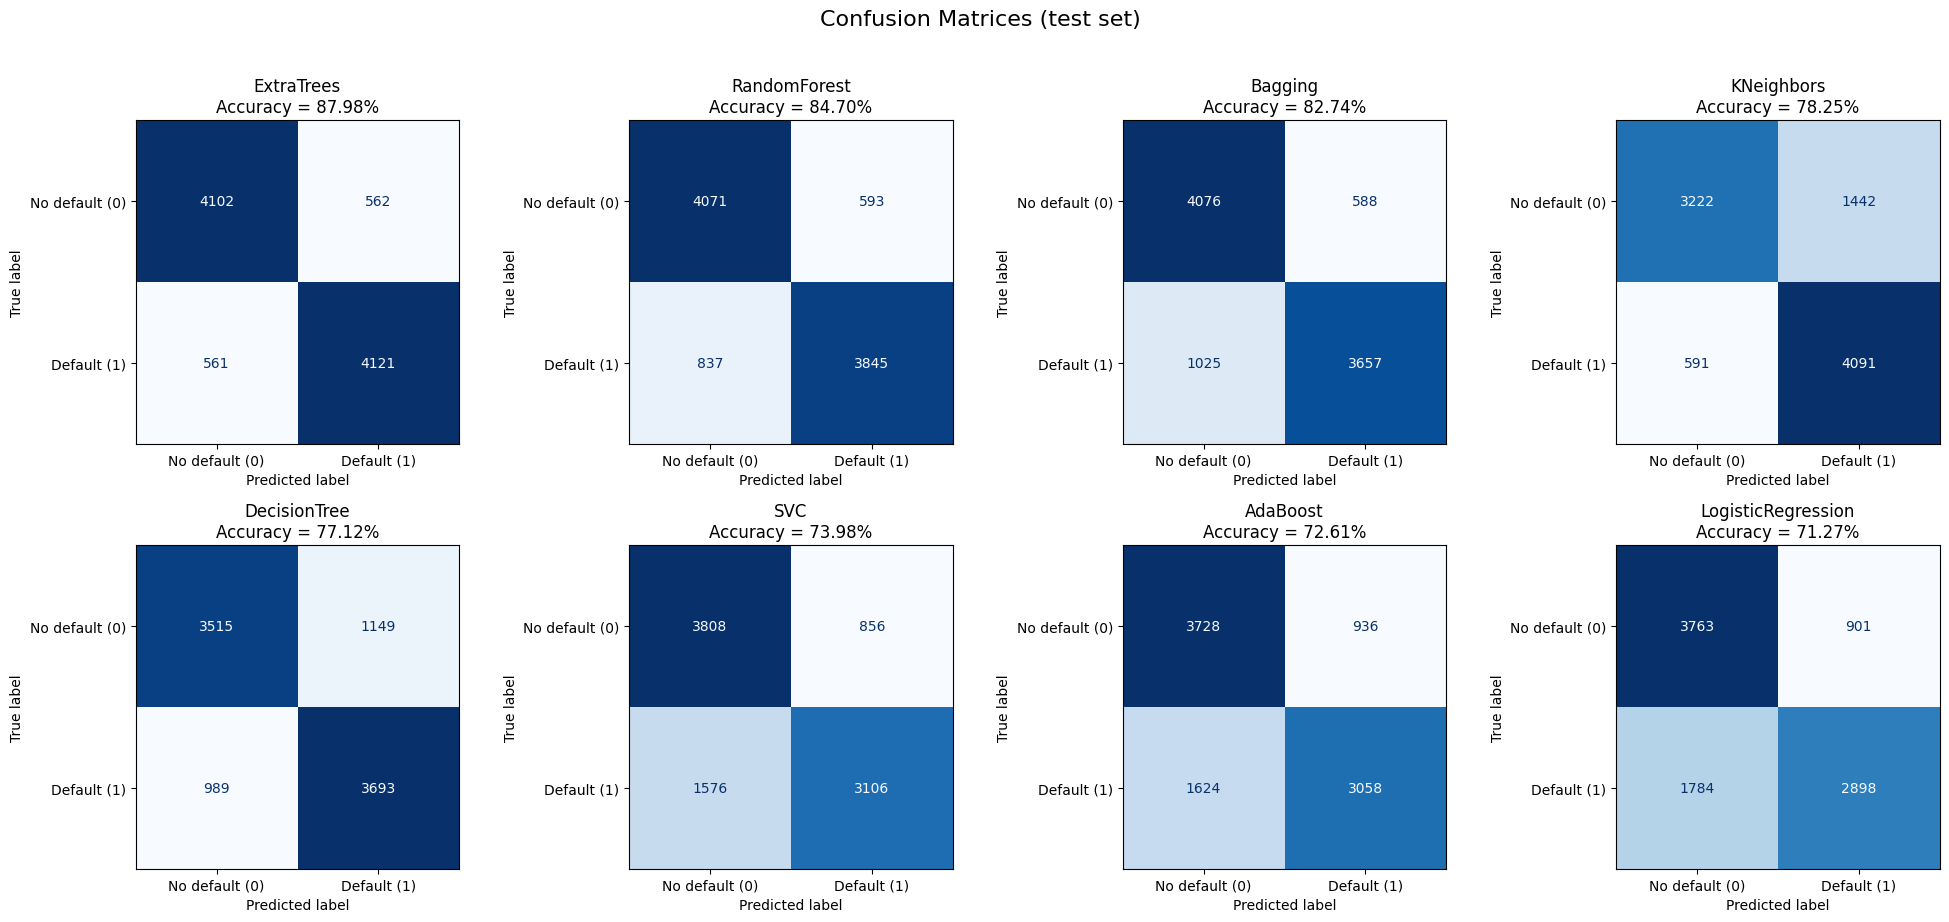

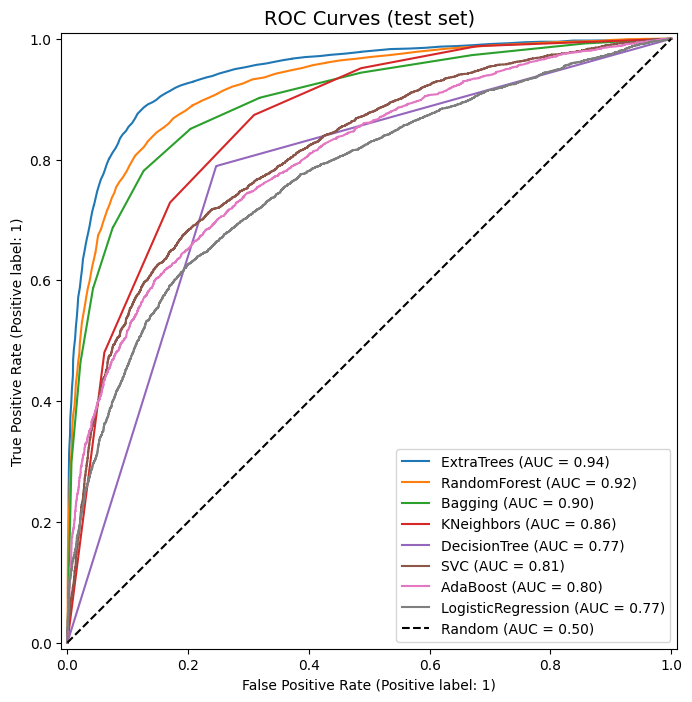


Best model on the test set: ExtraTrees (0.8798)

5-Fold Cross-Validation Accuracy — ExtraTrees
  Fold 1: 0.8812
  Fold 2: 0.8818
  Fold 3: 0.8804
  Fold 4: 0.8764
  Fold 5: 0.8800
  Mean : 0.8800
  Std  : 0.0019


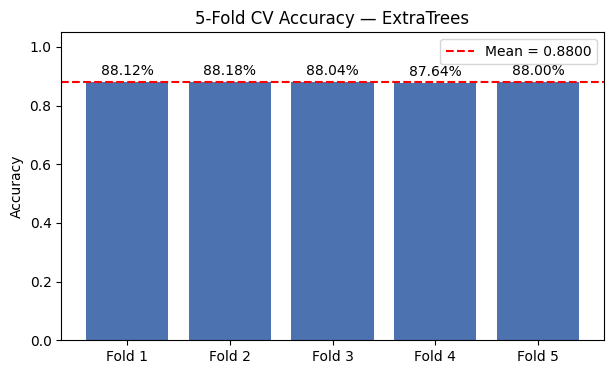

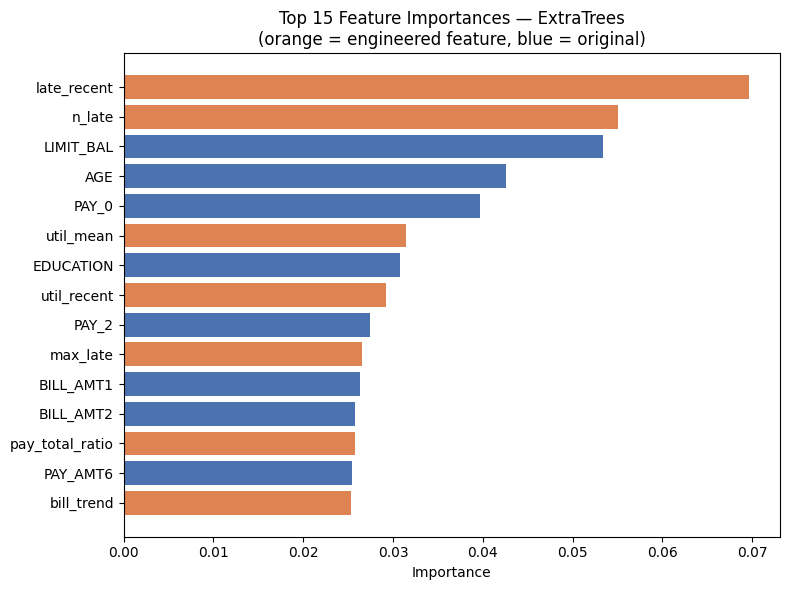

In [3]:
# =====================================================================
# CODE 3: Train 8 models on the SMOTE dataset (from Code 1)
#   - Feature engineering (13 new features from the original 23)
#   - 80/20 train/test split
#   - Class-wise precision / recall / F1 / accuracy (class 0 and class 1)
#   - Confusion matrix plots
#   - ROC curves
#   - 5-fold cross-validation accuracy for the best model
# Google Colab — run Code 1 first (it creates /content/credit_card_smote.csv)
# =====================================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

DATA_PATH = "/content/credit_card_smote.csv"
TARGET = "default payment next month"
RANDOM_STATE = 42
USE_FEATURE_ENGINEERING = True     # set to False to run with only the original 23 features

# ---------- 1. Load SMOTE dataset ----------
df = pd.read_csv(DATA_PATH)
X = df.drop(columns=[TARGET])
y = df[TARGET]

# ---------- 1b. Feature engineering ----------
# Every new feature is computed row by row from that client's own values only,
# so it can be done before the split without using information from other rows.
PAY_COLS  = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]           # repayment status, newest -> oldest
BILL_COLS = [f"BILL_AMT{i}" for i in range(1, 7)]                          # bill amount,       newest -> oldest
PAMT_COLS = [f"PAY_AMT{i}" for i in range(1, 7)]                           # amount paid,       newest -> oldest

def add_features(X):
    X = X.copy()
    pay, bill, pamt = X[PAY_COLS], X[BILL_COLS], X[PAMT_COLS]
    limit = X["LIMIT_BAL"]

    # Repayment behaviour
    X["n_late"]          = (pay > 0).sum(axis=1)                 # months with a payment delay (out of 6)
    X["max_late"]        = pay.max(axis=1)                       # worst delay in months
    X["late_recent"]     = (X[["PAY_0", "PAY_2"]] > 0).sum(axis=1)   # delays in the last 2 months
    X["zero_pay_months"] = (pamt <= 0).sum(axis=1)               # months with no payment at all

    # Credit utilisation
    X["util_recent"] = X["BILL_AMT1"] / limit                    # latest bill / credit limit
    X["util_mean"]   = bill.mean(axis=1) / limit                 # average bill / credit limit

    # How much of the previous bill was paid each month (clipped to avoid huge ratios when the bill is ~0)
    for i in range(1, 6):
        X[f"pay_ratio{i}"] = (X[f"PAY_AMT{i}"] / X[f"BILL_AMT{i+1}"].clip(lower=1)).clip(0, 5)
    X["pay_total_ratio"] = (pamt.sum(axis=1) / bill.sum(axis=1).clip(lower=1)).clip(0, 5)

    # Trend of the bill over 6 months (positive = debt is growing)
    X["bill_trend"] = X["BILL_AMT1"] - X["BILL_AMT6"]
    return X

if USE_FEATURE_ENGINEERING:
    X = add_features(X)
    print(f"Feature engineering ON: {X.shape[1]} features (23 original + {X.shape[1] - 23} new)")
else:
    print(f"Feature engineering OFF: {X.shape[1]} original features")

# ---------- 1c. Split 80/20 ----------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")
print("Test class counts:", y_test.value_counts().sort_index().to_dict(), "\n")

# ---------- 2. Models ----------
models = {
    "ExtraTrees":         ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "RandomForest":       RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "Bagging":            BaggingClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "KNeighbors":         KNeighborsClassifier(),
    "DecisionTree":       DecisionTreeClassifier(random_state=RANDOM_STATE),
    "AdaBoost":           AdaBoostClassifier(random_state=RANDOM_STATE),
    "SVC":                SVC(random_state=RANDOM_STATE),            # slowest (~1-2 min)
    "LogisticRegression": LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
}

def make_pipeline(model):
    return Pipeline([("scaler", StandardScaler()), ("model", model)])

# ---------- 3. Train, predict, class-wise metrics ----------
fitted, rows = {}, []
for name, model in models.items():
    t0 = time.time()
    pipe = make_pipeline(model).fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    fitted[name] = (pipe, y_pred)

    prec, rec, f1, sup = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1], zero_division=0)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    class_acc = cm.diagonal() / cm.sum(axis=1)          # per-class accuracy (= recall of that class)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Class 0 Precision": prec[0], "Class 0 Recall": rec[0], "Class 0 F1": f1[0], "Class 0 Accuracy": class_acc[0],
        "Class 1 Precision": prec[1], "Class 1 Recall": rec[1], "Class 1 F1": f1[1], "Class 1 Accuracy": class_acc[1],
        "Time (s)": time.time() - t0,
    })
    print(f"{name}: accuracy = {rows[-1]['Accuracy']:.4f}  ({rows[-1]['Time (s)']:.1f}s)")

results = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)

# ---------- 4. Class-wise result for every model ----------
print("\n" + "=" * 70)
print("CLASS-WISE RESULTS (test set)")
print("=" * 70)
for name in results["Model"]:
    _, y_pred = fitted[name]
    print(f"\n----- {name} -----")
    print(classification_report(y_test, y_pred, labels=[0, 1],
                                target_names=["Class 0 (No default)", "Class 1 (Default)"], digits=4))

# Summary table: class 0 and class 1 for each model
summary = results.set_index("Model")
class_table = pd.concat({
    "Class 0": summary[["Class 0 Precision", "Class 0 Recall", "Class 0 F1", "Class 0 Accuracy"]]
               .set_axis(["Precision", "Recall", "F1", "Accuracy"], axis=1),
    "Class 1": summary[["Class 1 Precision", "Class 1 Recall", "Class 1 F1", "Class 1 Accuracy"]]
               .set_axis(["Precision", "Recall", "F1", "Accuracy"], axis=1),
}, axis=1)
class_table.insert(0, ("Overall", "Accuracy"), summary["Accuracy"])
print("\nSUMMARY TABLE (%)")
display((class_table * 100).round(2))

results.to_csv("/content/model_results_classwise.csv", index=False)

# ---------- 5. Confusion matrix plots ----------
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, name in zip(axes.ravel(), results["Model"]):
    _, y_pred = fitted[name]
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=[0, 1], display_labels=["No default (0)", "Default (1)"],
        cmap="Blues", colorbar=False, values_format="d", ax=ax)
    acc = results.loc[results["Model"] == name, "Accuracy"].item()
    ax.set_title(f"{name}\nAccuracy = {acc:.2%}", fontsize=12)
plt.suptitle("Confusion Matrices (test set)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# ---------- 6. ROC curves (all models on one plot) ----------
fig, ax = plt.subplots(figsize=(9, 8))
for name in results["Model"]:
    pipe, _ = fitted[name]
    # uses predict_proba when available, otherwise decision_function (e.g. SVC)
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.50)")
ax.set_title("ROC Curves (test set)", fontsize=14)
ax.legend(loc="lower right")
plt.show()

# ---------- 7. 5-fold cross-validation for the best model ----------
best_name = results.loc[0, "Model"]
print(f"\nBest model on the test set: {best_name} ({results.loc[0, 'Accuracy']:.4f})")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(make_pipeline(models[best_name]), X, y, cv=cv, scoring="accuracy", n_jobs=-1)

print(f"\n5-Fold Cross-Validation Accuracy — {best_name}")
for i, s in enumerate(cv_scores, 1):
    print(f"  Fold {i}: {s:.4f}")
print(f"  Mean : {cv_scores.mean():.4f}")
print(f"  Std  : {cv_scores.std():.4f}")

plt.figure(figsize=(7, 4))
bars = plt.bar([f"Fold {i}" for i in range(1, 6)], cv_scores, color="#4C72B0")
plt.bar_label(bars, labels=[f"{s:.2%}" for s in cv_scores], padding=3)
plt.axhline(cv_scores.mean(), color="red", linestyle="--", label=f"Mean = {cv_scores.mean():.4f}")
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title(f"5-Fold CV Accuracy — {best_name}")
plt.legend()
plt.show()

# ---------- 8. Feature importance of the best model (top 15) ----------
best_pipe, _ = fitted[best_name]
model = best_pipe.named_steps["model"]
if hasattr(model, "feature_importances_"):
    imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=True).tail(15)
    new_feats = set(X.columns) - set(df.columns)
    colors = ["#DD8452" if f in new_feats else "#4C72B0" for f in imp.index]
    plt.figure(figsize=(8, 6))
    plt.barh(imp.index, imp.values, color=colors)
    plt.xlabel("Importance")
    plt.title(f"Top 15 Feature Importances — {best_name}\n(orange = engineered feature, blue = original)")
    plt.tight_layout()
    plt.show()


In [4]:
best_model = fitted[best_name][0]

Best Model: ExtraTrees
SHAP shape: (1000, 36)


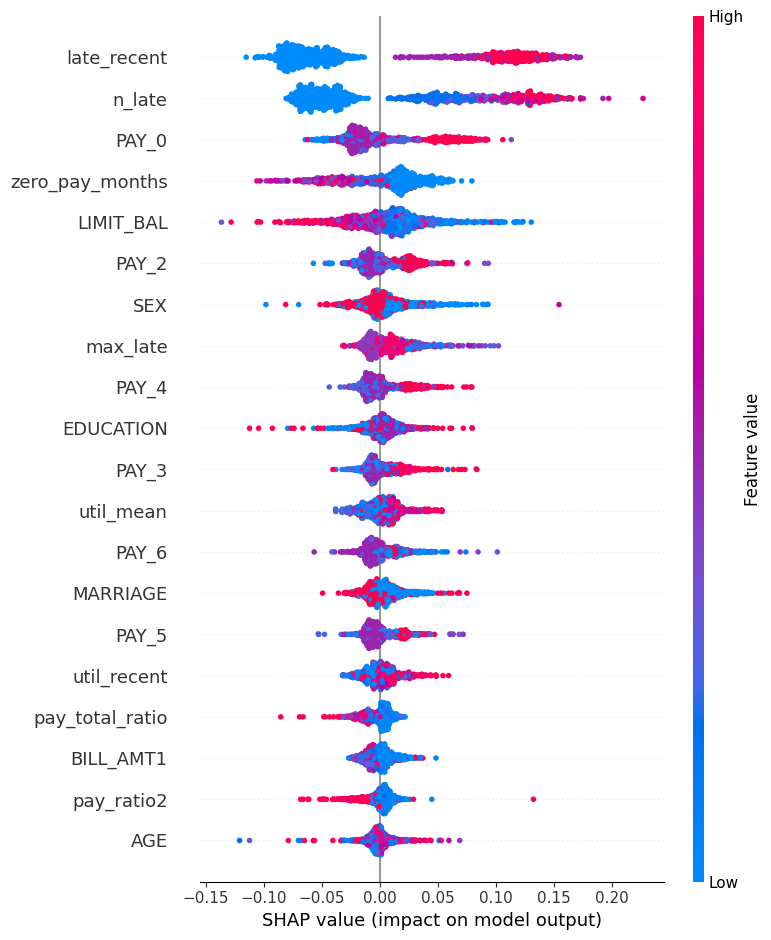

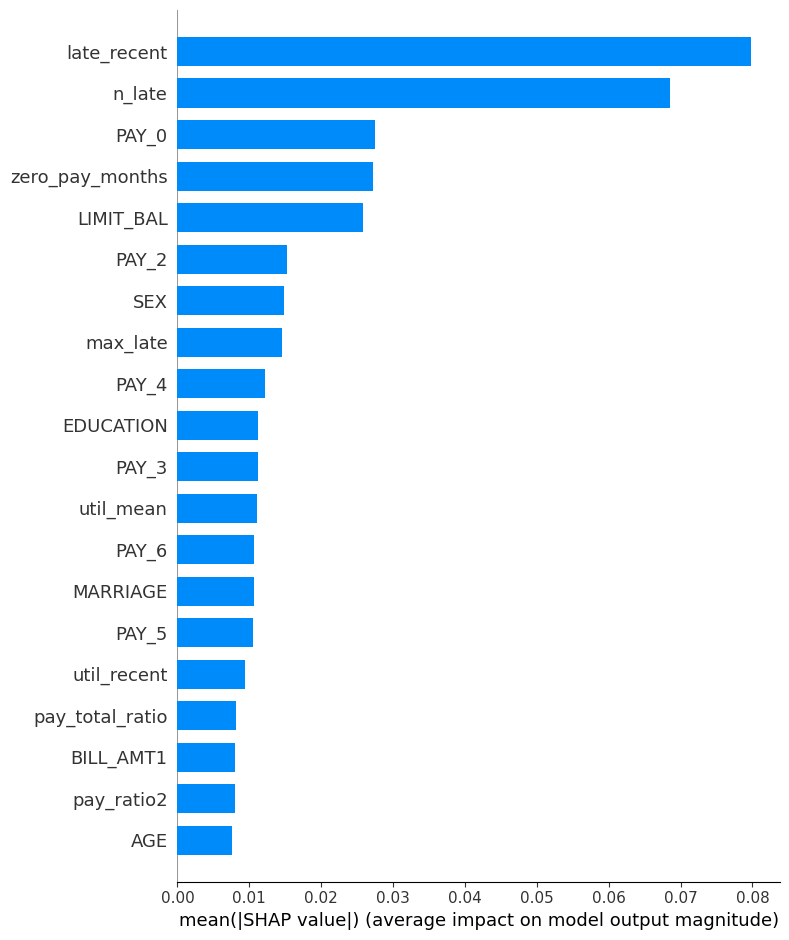

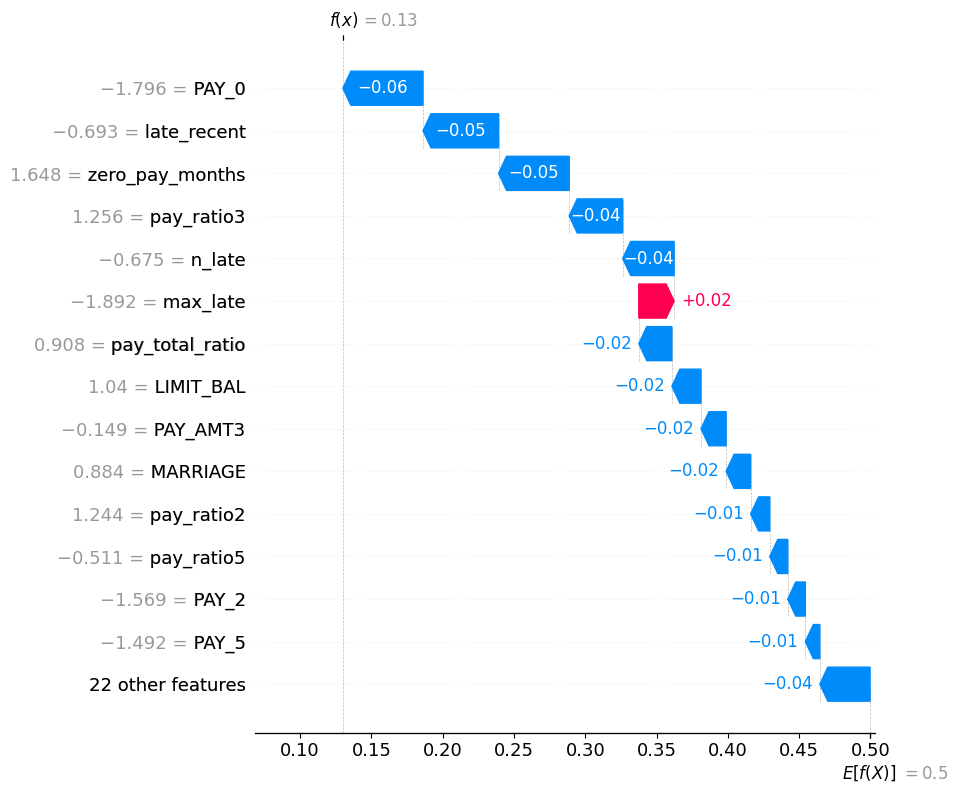


Top SHAP Features


,Feature,Mean_ABS_SHAP
25,late_recent,0.079841
23,n_late,0.068553
5,PAY_0,0.027515
26,zero_pay_months,0.027250
0,LIMIT_BAL,0.025769
6,PAY_2,0.015293
1,SEX,0.014828
24,max_late,0.014495
8,PAY_4,0.012247
2,EDUCATION,0.011244



SHAP analysis completed successfully!


In [5]:
# ============================================================
# Explainable AI: SHAP Interpretation
# Final Feature-Engineered Best Model
# Compatible with SHAP >= 0.20
# ============================================================

!pip install shap -q


import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Extract final trained model from Cell 3
# ------------------------------------------------------------

best_pipe = fitted[best_name][0]

final_model = best_pipe.named_steps["model"]
scaler = best_pipe.named_steps["scaler"]


print("Best Model:", best_name)



# ------------------------------------------------------------
# 2. Transform test data using trained scaler
# ------------------------------------------------------------

X_test_scaled = scaler.transform(X_test)



# ------------------------------------------------------------
# 3. Select representative samples
# ------------------------------------------------------------

sample_size = min(1000, X_test_scaled.shape[0])


X_shap_scaled = X_test_scaled[:sample_size]


# Keep original feature names
X_shap = pd.DataFrame(
    X_shap_scaled,
    columns=X_test.columns
)



# ------------------------------------------------------------
# 4. Create SHAP Explainer
# ------------------------------------------------------------

explainer = shap.TreeExplainer(final_model)



# Calculate SHAP values

shap_values = explainer.shap_values(X_shap_scaled)



# ------------------------------------------------------------
# 5. Handle Binary Classification Output
# ------------------------------------------------------------

if isinstance(shap_values, list):

    # Older SHAP versions
    shap_class1 = shap_values[1]


elif isinstance(shap_values, np.ndarray) and len(shap_values.shape) == 3:

    # New multi-output SHAP format
    shap_class1 = shap_values[:, :, 1]


else:

    # Single output
    shap_class1 = shap_values



print("SHAP shape:", shap_class1.shape)



# ============================================================
# 6. Global SHAP Summary Plot
# ============================================================

plt.figure(figsize=(10,7))

shap.summary_plot(
    shap_class1,
    X_shap,
    max_display=20
)

plt.show()



# ============================================================
# 7. SHAP Feature Importance Ranking
# ============================================================

plt.figure(figsize=(10,7))

shap.summary_plot(
    shap_class1,
    X_shap,
    plot_type="bar",
    max_display=20
)

plt.show()



# ============================================================
# 8. Individual Customer Explanation
#    SHAP Waterfall Plot (Latest API)
# ============================================================


customer_id = 10



# Get expected/base value

if isinstance(explainer.expected_value, np.ndarray):

    base_value = explainer.expected_value[1]


elif isinstance(explainer.expected_value, list):

    base_value = explainer.expected_value[1]


else:

    base_value = explainer.expected_value



# Create SHAP Explanation object

customer_explanation = shap.Explanation(

    values = shap_class1[customer_id],

    base_values = base_value,

    data = X_shap.iloc[customer_id],

    feature_names = X_shap.columns

)



# Plot waterfall

shap.plots.waterfall(
    customer_explanation,
    max_display=15
)


plt.show()



# ============================================================
# 9. Save SHAP Importance Table
# ============================================================

importance_df = pd.DataFrame({

    "Feature": X_shap.columns,

    "Mean_ABS_SHAP": np.abs(shap_class1).mean(axis=0)

})


importance_df = importance_df.sort_values(
    by="Mean_ABS_SHAP",
    ascending=False
)


print("\nTop SHAP Features")

display(importance_df.head(20))



# Save result

importance_df.to_csv(
    "SHAP_feature_importance.csv",
    index=False
)


print("\nSHAP analysis completed successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 4.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Best Model: ExtraTrees


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


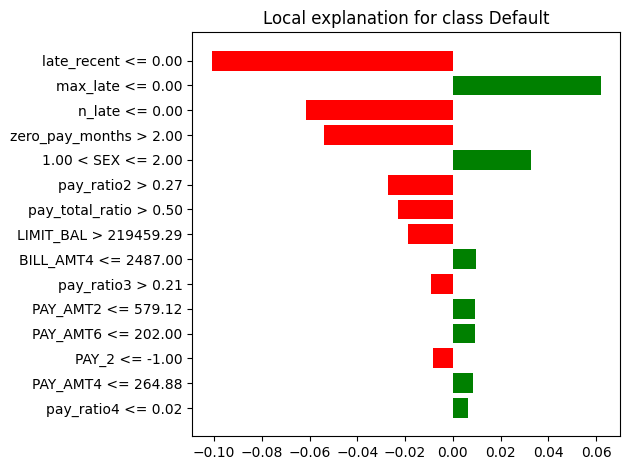

,Feature,Contribution
0,late_recent <= 0.00,-0.100839
1,max_late <= 0.00,0.061798
2,n_late <= 0.00,-0.061555
3,zero_pay_months > 2.00,-0.053929
4,1.00 < SEX <= 2.00,0.032728
5,pay_ratio2 > 0.27,-0.027089
6,pay_total_ratio > 0.50,-0.023132
7,LIMIT_BAL > 219459.29,-0.018811
8,BILL_AMT4 <= 2487.00,0.009558
9,pay_ratio3 > 0.21,-0.009264


In [6]:
# ============================================================
# Explainable AI: LIME Local Interpretation
# Final Feature-Engineered Best Model
# ============================================================

!pip install lime -q

from lime.lime_tabular import LimeTabularExplainer
import matplotlib.pyplot as plt
import pandas as pd


# ------------------------------------------------------------
# 1. Use final trained pipeline from Cell 3
# ------------------------------------------------------------

best_pipe = fitted[best_name][0]

print("Best Model:", best_name)


# ------------------------------------------------------------
# 2. Create LIME Explainer
# ------------------------------------------------------------

lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=[
        "No Default",
        "Default"
    ],
    mode="classification",
    random_state=42
)


# ------------------------------------------------------------
# 3. Select one customer from test data
# ------------------------------------------------------------

customer_id = 10


# ------------------------------------------------------------
# 4. Generate explanation
# ------------------------------------------------------------

lime_exp = lime_explainer.explain_instance(
    X_test.iloc[customer_id].values,
    best_pipe.predict_proba,
    num_features=15
)


# ------------------------------------------------------------
# 5. Display LIME explanation
# ------------------------------------------------------------

lime_exp.show_in_notebook()


# Plot

fig = lime_exp.as_pyplot_figure()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Save explanation table
# ------------------------------------------------------------

lime_result = pd.DataFrame(
    lime_exp.as_list(),
    columns=[
        "Feature",
        "Contribution"
    ]
)

display(lime_result)


lime_result.to_csv(
    "/content/LIME_customer_explanation.csv",
    index=False
)